epoch    0 | MSE: 19.6898
epoch    1 | MSE: 6.6450
epoch    2 | MSE: 7.6507
epoch    3 | MSE: 6.6746
epoch    4 | MSE: 5.8341
epoch    5 | MSE: 5.1193
epoch    6 | MSE: 4.5137
epoch    7 | MSE: 4.0036
epoch    8 | MSE: 3.5761
epoch    9 | MSE: 3.2192
epoch   10 | MSE: 2.9221
epoch   11 | MSE: 2.6748
epoch   12 | MSE: 2.4687
epoch   13 | MSE: 2.2964
epoch   14 | MSE: 2.1516
epoch   15 | MSE: 2.0292
epoch   16 | MSE: 1.9249
epoch   17 | MSE: 1.8352
epoch   18 | MSE: 1.7575
epoch   19 | MSE: 1.6894
epoch   20 | MSE: 1.6291
epoch   21 | MSE: 1.5754
epoch   22 | MSE: 1.5269
epoch   23 | MSE: 1.4715
epoch   24 | MSE: 1.4177
epoch   25 | MSE: 1.3664
epoch   26 | MSE: 1.3230
epoch   27 | MSE: 1.2822
epoch   28 | MSE: 1.2431
epoch   29 | MSE: 1.2057
epoch   30 | MSE: 1.1697
epoch   31 | MSE: 1.1353
epoch   32 | MSE: 1.1022
epoch   33 | MSE: 1.0706
epoch   34 | MSE: 1.0452
epoch   35 | MSE: 1.0164
epoch   36 | MSE: 0.9921
epoch   37 | MSE: 0.9750
epoch   38 | MSE: 0.9515
epoch   39 | MSE: 0.9304

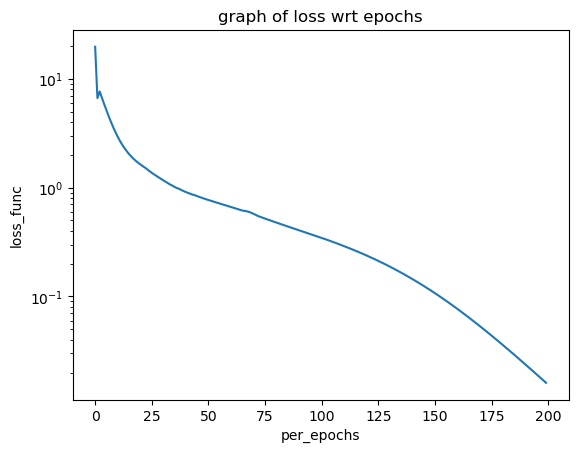

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#linear activation function
def linear(x):
  return x

#derivative of the linear function
#NOTE: we didn't use this because der_linear -> [1,1,1,1] so it just multiple with 1's
def der_linear(x):
  return np.ones_like(x)

#relu activation function
def relu(x):
  return np.maximum(0, x)

#derivative of the relu function
def der_relu(x):
  return (x > 0).astype(int)

def shape_output(y, ypred, mse):
  print(f"Predicted values: {ypred} | Actual values: {y} | Error: {y - ypred}")

  #printing the mse:
  print("MeanSquaredError: ", mse)

def loss_function(predictions, targets):
  ypred = np.array(predictions).flatten()
  sq_error = (targets - ypred) ** 2
  mse = np.sum(sq_error) / len(sq_error)
  return mse

def derloss_o_weights(hidden_outputs, y, ypred):
  # derivative wrt ypred
  loss_grad = 2 * (ypred - y)

  # derivative wrt output_weights
  der_loss_weights = loss_grad * hidden_outputs
  
  # derivative wrt output_weights
  der_loss_bias = np.array([loss_grad]) 

  return loss_grad, der_loss_weights, der_loss_bias

# NOTE: loss_gred->loss gradient | h_weights -> hidden weights | actn_der -> derivative of activation func
# NOTE: z_output_pa -> z value at pre activation func, X -> inputs 
def derloss_h_weights(loss_gred, h_weights, actn_der, z_output_pa, X):

  # derivative wrt hj
  der_loss_h = loss_gred * h_weights

  # derivative of relu
  actn_der_z = actn_der(z_output_pa)

  # derivative wrt zj
  der_loss_zj = der_loss_h * actn_der_z

  #derivative wrt z_w
  der_loss_zw =   np.outer(der_loss_zj,X)

  #derivative wrt z_b
  der_loss_zb =  der_loss_zj[0] 

  return der_loss_zw, der_loss_zb

# neuron calculation
#NOTE: each neuron calculation is generalized here:
def forward_layer(inputs, weights, biases, activation):
  h_val = np.array([])
  z_val = np.array([])

  for i_w in range(len(weights)):
    
    z = np.sum(weights[i_w] * inputs)
    z += biases[i_w]

    z_val = np.append(z_val, z)
    h_val = np.append(h_val, activation(z))

  return z_val, h_val

#NOTE: predict is used after training
def predict(
    X, hidden_w,hidden_b, 
    output_w, output_b, hidden_act, output_act
):
  pred = []
  for x in X:
    _, hidden_outputs = forward_layer(x, hidden_w, hidden_b, hidden_act)
    _, prediction = forward_layer(hidden_outputs, output_w, output_b, output_act)
    pred.append(prediction[0])

  return np.array(pred)

# MLP_demonstration:
def mini_mlp(
    X,y, hidden_w,hidden_b,hidden_act   
    ,output_w,output_b,output_act, lr=0.01, epochs=100
):

  loss_history = []
  #training:
  for epoch in range(epochs):
    for i in range(len(X)):
      
      #calculating hj:
      z_output_pa, hidden_outputs = forward_layer(X[i], hidden_w, hidden_b, hidden_act)

      #calculating outputs:
      _, prediction = forward_layer(hidden_outputs, output_w, output_b, output_act)

      # getting the derivative's of output weights:bias
      loss_grad, grad_o_w, grad_o_b = derloss_o_weights(hidden_outputs,y[i],prediction[0])

      # # getting the derivative's of hidden weights:bias
      grad_z_w, grad_z_b = derloss_h_weights(loss_grad, output_w, der_relu, z_output_pa, X[i])

      # calculating the Wn for outputs weights and bias:
      hidden_w = hidden_w - lr * grad_z_w 
      hidden_b = hidden_b - lr * grad_z_b 

      # calculating the Wn for outputs weights and bias:
      output_w = output_w - lr * grad_o_w 
      output_b = output_b - lr * grad_o_b 

    ypred = predict(
      X, hidden_w, hidden_b, output_w, output_b, hidden_act, output_act
    )
    mse = loss_function(ypred, y)
    loss_history.append(mse)

    print(f"epoch {epoch:4d} | MSE: {mse:.4f}") 

  return hidden_w, hidden_b, output_w, output_b, loss_history


# Dataset
X = np.array([
    [1, 1],
    [2, 1],
    [1, 2],
    [2, 2],
    [3, 1]
])

#target
y = np.array([3, 6, 5, 8, 11])

#weights from input -> hidden layer
hidden_weights = np.array([
  [0.2, -0.3],
  [0.4,  0.1],
  [-0.2, 0.5]
])
hidden_bias = np.array([0.1,0.2,0.3])

#weights and bias from hidden -> output
output_weights = np.array([
    [0.1,-0.3,0.2]
  ])
output_bias = np.array([0.1])

#starting the mlp
#NOTE: training of the NeuralNetwork
h_w, h_b, o_w, o_b, history = mini_mlp(
  X,y, hidden_weights,hidden_bias, relu,   
  output_weights, output_bias, linear, 0.01, 200
)

#NOTE: equation: y = x1 ^ 2 + 2 * x2
X_test = np.array([
    [3, 2],
    [2, 3],
    [1, 3],
    [3, 3],
])
y_test = X_test[:, 0]**2 + 2 * X_test[:, 1]   # [13, 10, 7, 15]
test_pred = predict(X_test,h_w,h_b, o_w,o_b,relu, linear)
test_mse = loss_function(test_pred, y_test)
print("Predicted:", test_pred)
print("Actual:   ", y_test)
print("Test MSE: ", test_mse)

# plot the curve
plt.plot(history)
plt.xlabel("per_epochs")
plt.ylabel("loss_func")
plt.title("graph of loss wrt epochs")
plt.yscale("log")
plt.show()


In [26]:
import numpy as np
ls = np.array([[-5.98, 2.3, 4.5]])
lss = np.array([-5.98])

a = np.array([-5.98, 2.3, 4.5])
b = np.array([-5.98])

a = a - 0.01 * ls
b = b - 0.01 * lss 

print(a)
print(b)

[[-5.9202  2.277   4.455 ]]
[-5.9202]


In [42]:
a = np.array([])
print(a.shape)

(0,)


NOTES:
    ''' Important pnt:
    z += weights[i_w] * inputs
    so this error occurs during the adding of output layer addition as the input=[v1,v2,v3]
    also here z += does nothing because after weigh+inputs we are getting array of 2 elements
    and then we store that in output[] so basically [array([0.3, 0. , 0.6, 0.3, 0.1, 0.8])]
    and in the next output_layer calculation: this (6,) is multiple by weights which is (3,)
    '''
    - 